In [1]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

## 1. Load data

In [2]:
raw_df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(raw_df.shape)
raw_df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Clean data

In [4]:
df = raw_df.drop(columns=['customerID']).copy()

In [5]:
total_charges = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank = total_charges.isna()
print('Blank TotalCharges rows:', int(blank.sum()))
print('All of them have tenure == 0:', bool((df.loc[blank, 'tenure'] == 0).all()))


Blank TotalCharges rows: 11
All of them have tenure == 0: True


In [6]:
df['TotalCharges'] = total_charges.fillna(0.0)

In [7]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
assert df['Churn'].notna().all(), 'Unexpected values in the Churn column'
df['Churn'] = df['Churn'].astype(int)


In [8]:
print('Missing values:', int(df.isnull().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))


Missing values: 0
Duplicate rows: 22


In [9]:
categorical_cols = df.select_dtypes(exclude='number').columns.tolist()

for col in categorical_cols:
    print(col, df[col].unique().tolist())

gender ['Female', 'Male']
Partner ['Yes', 'No']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No phone service', 'No', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'Yes', 'No internet service']
OnlineBackup ['Yes', 'No', 'No internet service']
DeviceProtection ['No', 'Yes', 'No internet service']
TechSupport ['No', 'Yes', 'No internet service']
StreamingTV ['No', 'Yes', 'No internet service']
StreamingMovies ['No', 'Yes', 'No internet service']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['Yes', 'No']
PaymentMethod ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']


## 3. Exploratory data analysis

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


In [11]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


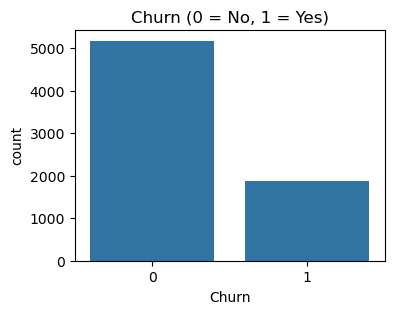

In [12]:
plt.figure(figsize=(4, 3))
sns.countplot(x=df['Churn'])
plt.title('Churn (0 = No, 1 = Yes)')
plt.show()

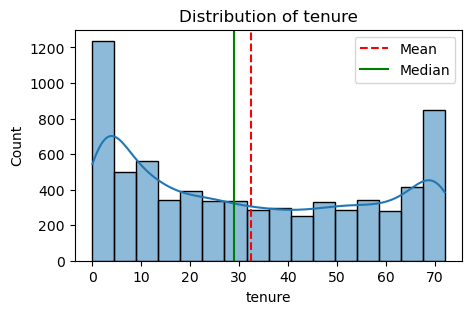

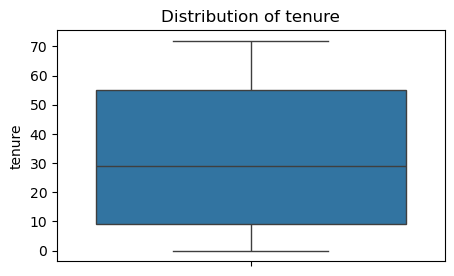

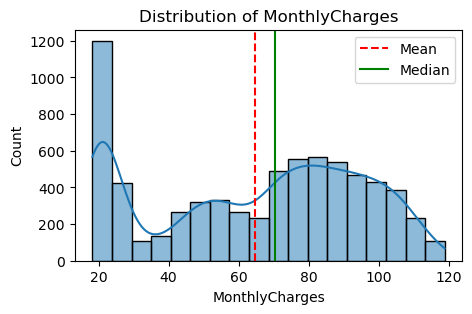

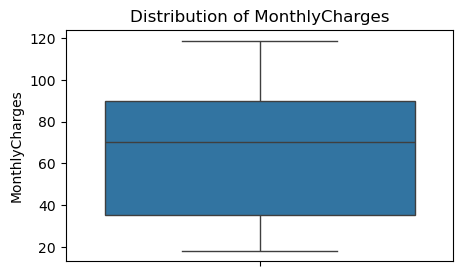

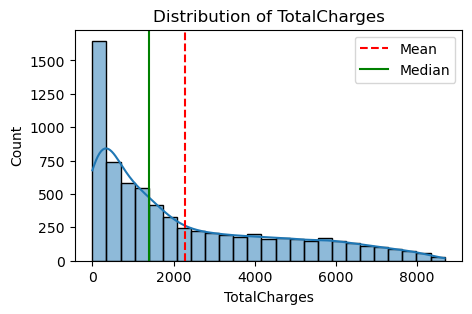

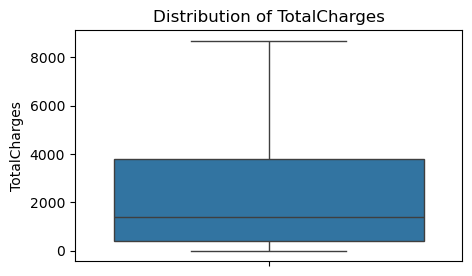

In [13]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']


def plot_histogram(data, column_name):
    plt.figure(figsize=(5, 3))
    sns.histplot(data[column_name], kde=True)
    plt.title(f'Distribution of {column_name}')
    plt.axvline(data[column_name].mean(), color='red', linestyle='--', label='Mean')
    plt.axvline(data[column_name].median(), color='green', linestyle='-', label='Median')
    plt.legend()
    plt.show()


def plot_boxplot(data, column_name):
    plt.figure(figsize=(5, 3))
    sns.boxplot(y=data[column_name])
    plt.title(f'Distribution of {column_name}')
    plt.ylabel(column_name)
    plt.show()


for col in numeric_cols:
    plot_histogram(df, col)
    plot_boxplot(df, col)

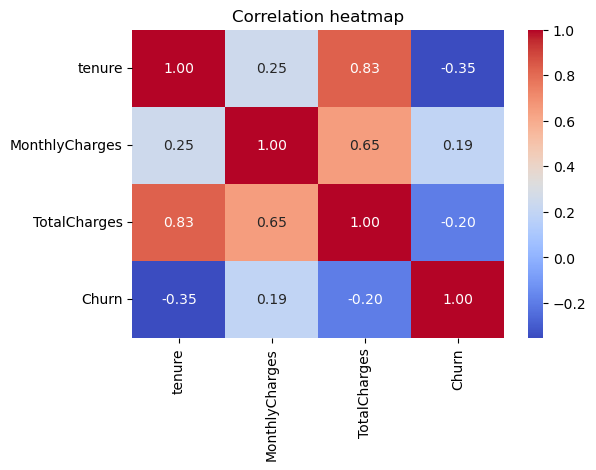

In [14]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[numeric_cols + ['Churn']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

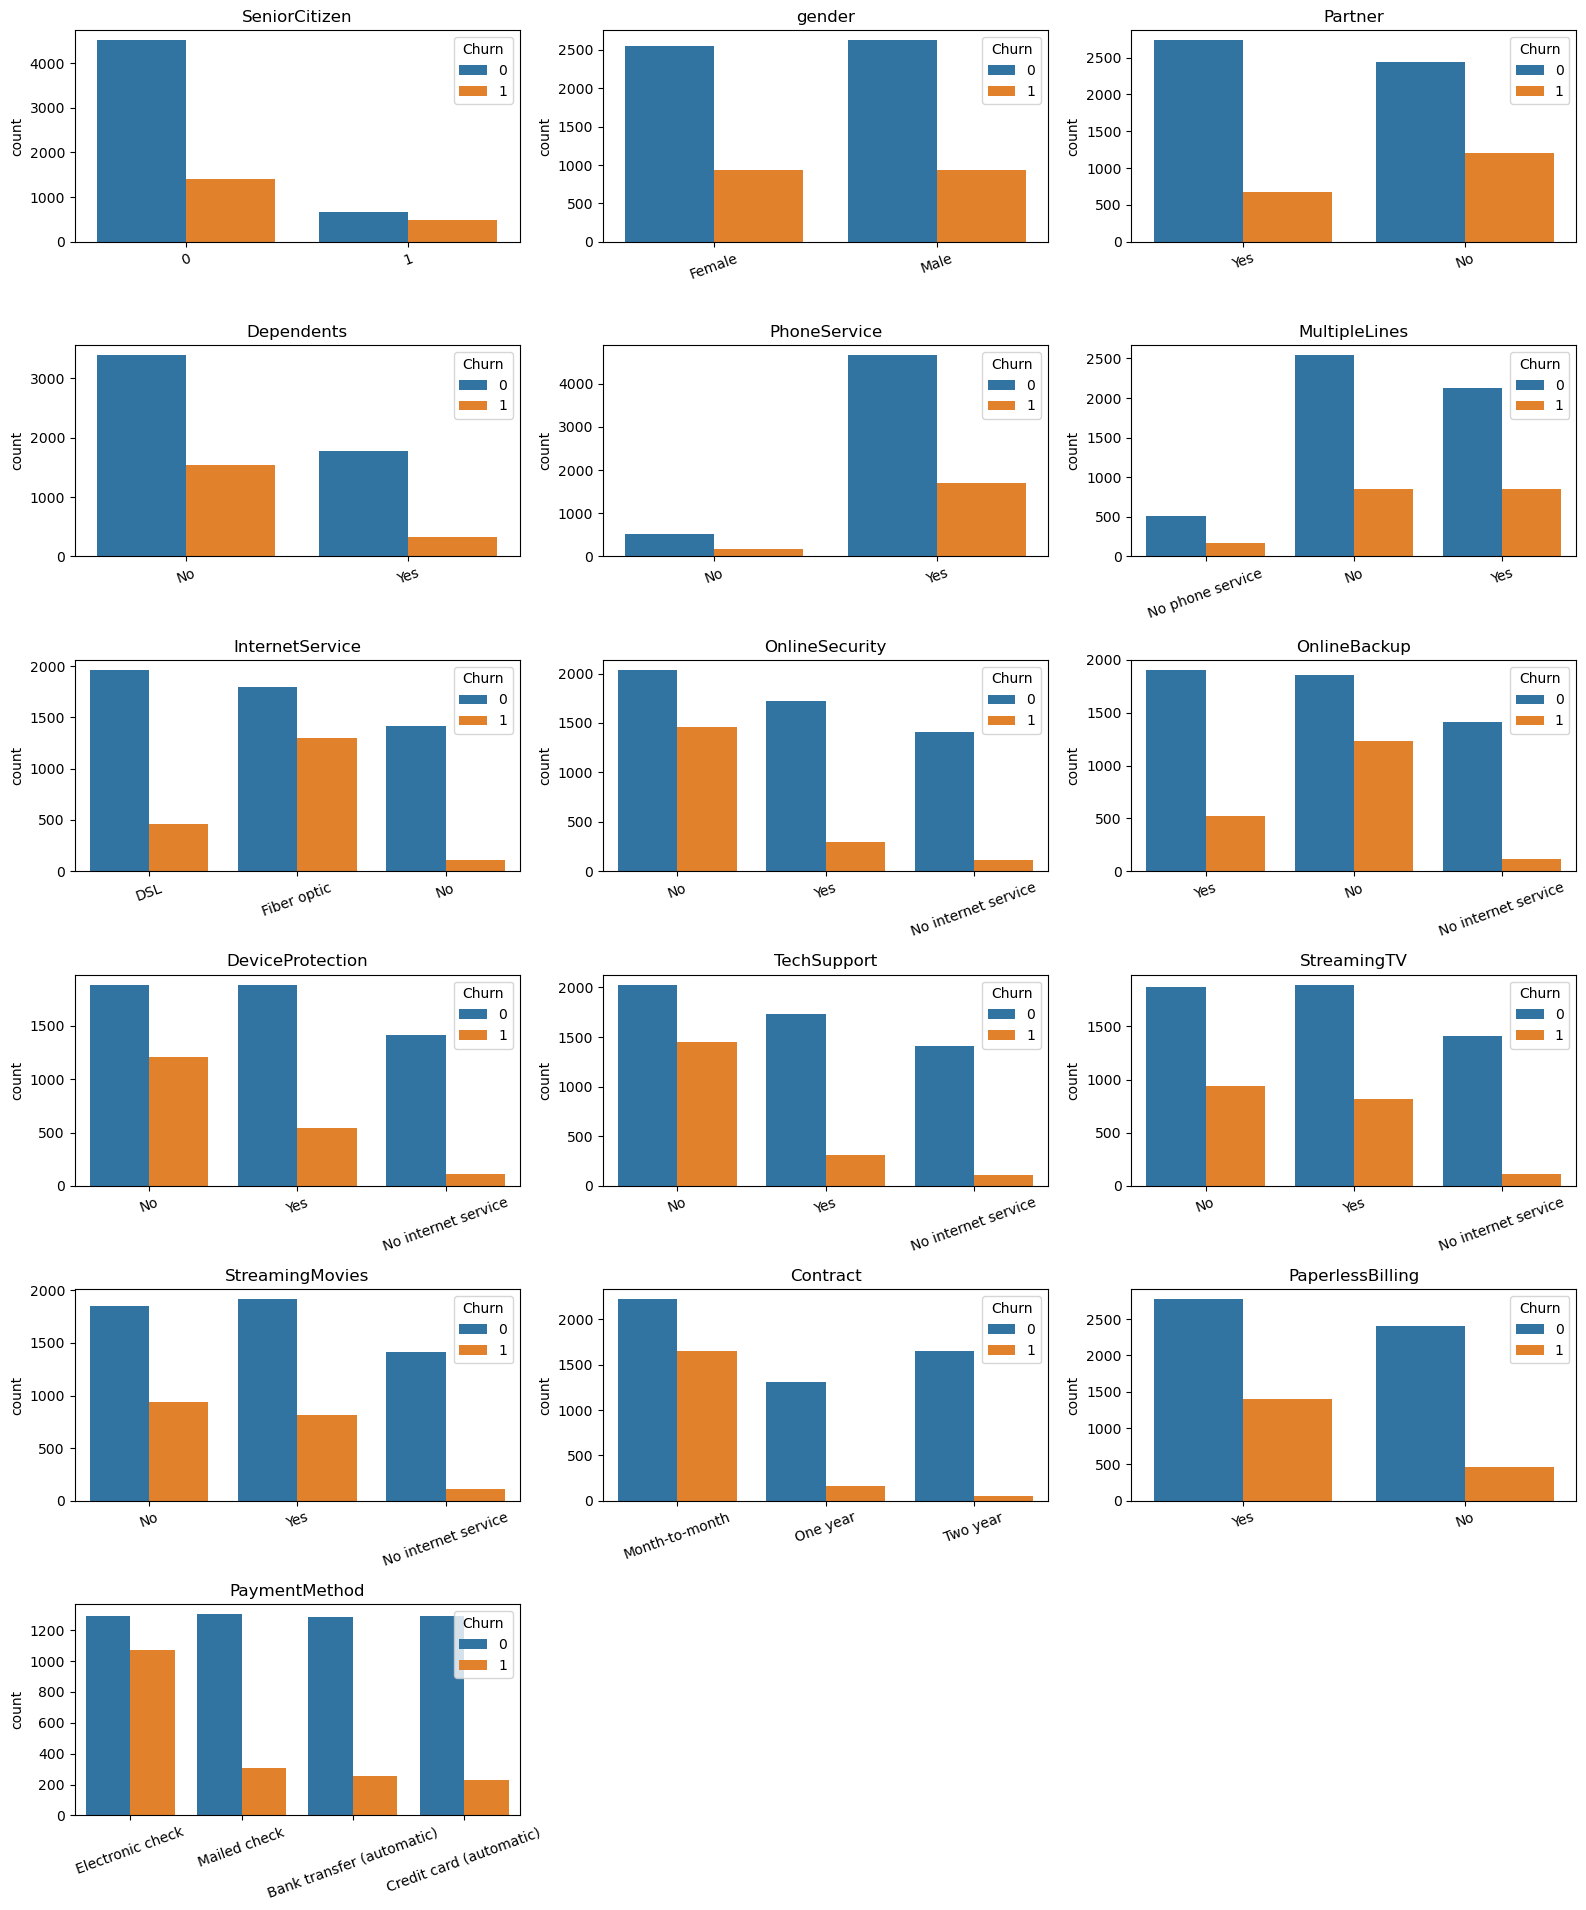

In [15]:
cat_features = ['SeniorCitizen'] + categorical_cols
n_cols = 3
n_rows = int(np.ceil(len(cat_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))
for ax, col in zip(axes.ravel(), cat_features):
    sns.countplot(data=df, x=col, hue='Churn', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
for ax in axes.ravel()[len(cat_features):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 4. Encode categorical features



In [16]:
df_encoded = df.copy()
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    encoders[col] = le

for col, le in encoders.items():
    assert le.classes_.dtype.kind in 'OUS', f'{col} encoder was fit on already-encoded data'

for col, le in encoders.items():
    print(col, '->', list(le.classes_))



gender -> ['Female', 'Male']
Partner -> ['No', 'Yes']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No', 'No phone service', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'No internet service', 'Yes']
OnlineBackup -> ['No', 'No internet service', 'Yes']
DeviceProtection -> ['No', 'No internet service', 'Yes']
TechSupport -> ['No', 'No internet service', 'Yes']
StreamingTV -> ['No', 'No internet service', 'Yes']
StreamingMovies -> ['No', 'No internet service', 'Yes']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['No', 'Yes']
PaymentMethod -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


In [17]:
with open('encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)

In [18]:
df_encoded.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


## 5. Train/test split



In [19]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [21]:
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train churn rate:', round(y_train.mean(), 3), '| Test churn rate:', round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19)
Train churn rate: 0.265 | Test churn rate: 0.265


## 6. Compare models


In [22]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
}

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [24]:
scoring = ['accuracy', 'precision', 'recall', 'f1']

In [25]:
rows = {}
for name, model in models.items():
    print(f'Cross-validating {name}...')
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', model),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: res[f'test_{m}'].mean() for m in scoring}

Cross-validating Decision Tree...


C:\Users\jihed\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\jihed\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\jihed\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\jihed\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

Cross-validating Random Forest...
Cross-validating XGBoost...


In [26]:
cv_results = pd.DataFrame(rows).T.round(3).sort_values('f1', ascending=False)


In [27]:
cv_results

,accuracy,precision,recall,f1
Random Forest,0.782,0.590,0.586,0.588
XGBoost,0.767,0.561,0.562,0.562
Decision Tree,0.723,0.479,0.533,0.505


## 7. Final model



In [28]:
best_name = cv_results['f1'].idxmax()
print('Selected model:', best_name)


Selected model: Random Forest


In [29]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(y_train_smote.value_counts())


Churn
0    4139
1    4139
Name: count, dtype: int64


In [30]:
final_model = clone(models[best_name])
final_model.fit(X_train_smote, y_train_smote)

RandomForestClassifier(random_state=42)

In [31]:
y_test_pred = final_model.predict(X_test)


In [32]:
print('Accuracy:', round(accuracy_score(y_test, y_test_pred), 4))
print()
print('Confusion matrix:')
print(confusion_matrix(y_test, y_test_pred))
print()
print(classification_report(y_test, y_test_pred, target_names=['No churn', 'Churn']))



Accuracy: 0.7786

Confusion matrix:
[[877 158]
 [154 220]]

              precision    recall  f1-score   support

    No churn       0.85      0.85      0.85      1035
       Churn       0.58      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



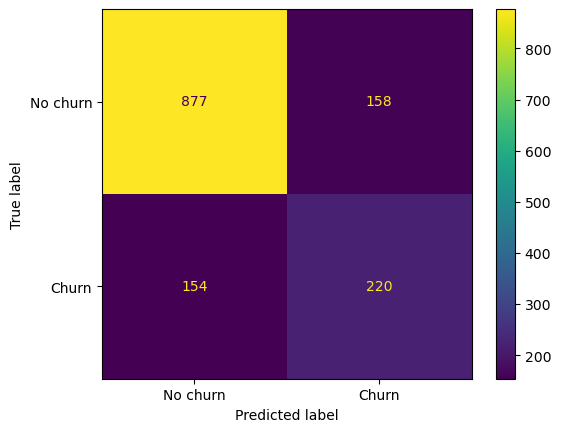

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=['No churn', 'Churn']
)
plt.show()

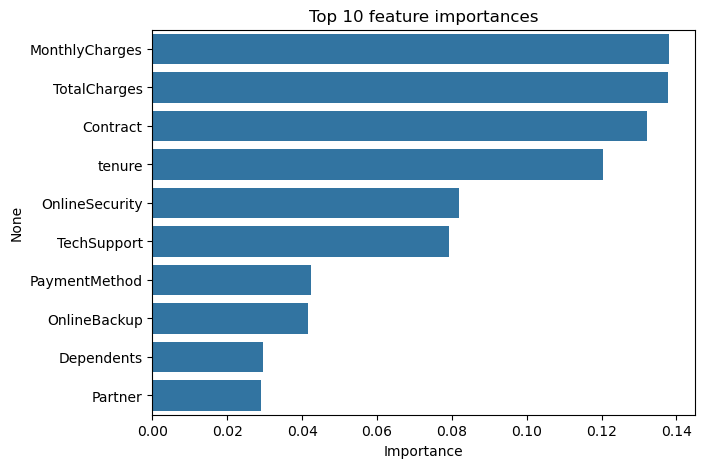

In [34]:
importances = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importances.head(10)

plt.figure(figsize=(7, 5))
sns.barplot(x=top.values, y=top.index)
plt.title('Top 10 feature importances')
plt.xlabel('Importance')
plt.show()

## 8. Save the model


In [35]:
model_data = {'model': final_model, 'features_names': X.columns.tolist()}

with open('customer_churn_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

with open('customer_churn_model.pkl', 'rb') as f:
    check = pickle.load(f)
assert (check['model'].predict(X_test[check['features_names']]) == y_test_pred).all()
print('Saved model reloads and reproduces the test predictions.')

Saved model reloads and reproduces the test predictions.
